# Анализ строительной отрасли России

In [1]:

from pathlib import Path
import re
import time
import subprocess
import tempfile

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from tqdm.auto import tqdm
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

sns.set_theme(style="whitegrid")
BASE_DIR = Path.cwd()
REGISTRY_PARQUET = BASE_DIR / "Реестр.parquet"
REGISTRY_XLSX = BASE_DIR / "Реестр.xlsx"
FINANCIAL_FILE = BASE_DIR / "financial_data.parquet"
PROCESSED_FILE = BASE_DIR / "financial_processed.parquet"
FIGURE_DIR = BASE_DIR / "figures"
FIGURE_DIR.mkdir(exist_ok=True)
YEARS = range(2020, 2026)

## 2. Загрузка реестра

In [2]:

if REGISTRY_PARQUET.exists():
    registry_raw = pd.read_parquet(REGISTRY_PARQUET)
elif REGISTRY_XLSX.exists():

    registry_raw = pd.read_excel(REGISTRY_XLSX, engine="calamine", dtype=str)
else:
    raise FileNotFoundError("Не найден ни Реестр.parquet, ни Реестр.xlsx")

registry = registry_raw.copy()
if not any(str(c).strip().lower() == "инн" for c in registry.columns):
    header_row = None
    for i in range(min(10, len(registry))):
        values = registry.iloc[i].astype(str).str.strip().str.lower().tolist()
        if "инн" in values:
            header_row = i
            break
    if header_row is None:
        raise ValueError("Не удалось определить строку заголовков: столбец ИНН не найден")
    registry.columns = registry.iloc[header_row].astype(str).str.strip()
    registry = registry.iloc[header_row + 1:].copy()

registry.columns = [str(c).strip() for c in registry.columns]
display(registry.head())

,№ п/п,Наименование / ФИО,Тип субъекта,Категория,ОГРН,ИНН,Основной вид деятельности,Регион,Район,Город,...,Дата исключения из реестра,Телефон,E-mail,WWW,Наличие лицензий,"Наличие заключенных договоров, контрактов","Производство инновационной, высокотехнологичной продукции",Участие в программах партнерства,Является социальным предприятием,Среднесписочная численность работников за предшествующий календарный год
2,1,""" МЕГАПОЛИС "" ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВ...",Юридическое лицо,Не является субъектом МСП,1027800523376,7801190028,41.2 Строительство жилых и нежилых зданий,78 - г.Санкт-Петербург,<NA>,<NA>,...,10.10.2021,<NA>,<NA>,<NA>,Нет,Нет,Нет,Нет,Нет,<NA>
3,2,""" СТАЛЬИНВЕСТСТРОЙ "" ОБЩЕСТВО С ОГРАНИЧЕННОЙ О...",Юридическое лицо,Не является субъектом МСП,1037800033545,7801227976,41.20 Строительство жилых и нежилых зданий,78 - г.Санкт-Петербург,<NA>,<NA>,...,10.08.2018,<NA>,<NA>,<NA>,Нет,Нет,Нет,Нет,Нет,<NA>
4,3,""" СТРОЙТЕХНИКА - М "" ОБЩЕСТВО С ОГРАНИЧЕННОЙ О...",Юридическое лицо,Не является субъектом МСП,1025204418293,5263039399,41.20 Строительство жилых и нежилых зданий,52 - Нижегородская область,<NA>,г Нижний Новгород,...,10.07.2022,<NA>,<NA>,<NA>,Нет,Нет,Нет,Нет,Нет,<NA>
5,4,"""БАЗИС"" ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ",Юридическое лицо,Микропредприятие,1025204411682,5263025484,41.20 Строительство жилых и нежилых зданий,52 - Нижегородская область,<NA>,г Нижний Новгород,...,<NA>,<NA>,<NA>,<NA>,Нет,Нет,Нет,Нет,Нет,1
6,5,"""БЕЛАГ"" ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ",Юридическое лицо,Не является субъектом МСП,1037800039276,7801123215,41.20 Строительство жилых и нежилых зданий,78 - г.Санкт-Петербург,<NA>,<NA>,...,10.07.2021,<NA>,<NA>,<NA>,Нет,Нет,Нет,Нет,Нет,<NA>


## 3. Фильтрация компаний

In [3]:

required = ["ИНН", "Наименование / ФИО", "Тип субъекта", "Категория",
            "Основной вид деятельности", "Регион"]
missing = [column for column in required if column not in registry.columns]
if missing:
    raise ValueError(f"В реестре не найдены столбцы: {missing}")

registry["ИНН"] = registry["ИНН"].astype("string").str.strip().str.replace(r"\.0$", "", regex=True)
registry["Название"] = registry["Наименование / ФИО"].astype("string").str.strip()
registry["Тип субъекта"] = registry["Тип субъекта"].astype("string").str.strip()
registry["Категория"] = registry["Категория"].astype("string").str.strip()
registry["Основной ОКВЭД"] = registry["Основной вид деятельности"].astype("string").str.strip()
registry["Регион"] = registry["Регион"].astype("string").str.strip()

address_columns = [column for column in ["Регион", "Район", "Город", "Населенный пункт",
                                          "Улица", "Дом", "Корпус", "Квартира"]
                   if column in registry.columns]
registry["Адрес регистрации"] = registry[address_columns].fillna("").astype(str).apply(
    lambda row: ", ".join(value.strip() for value in row if value.strip() and value.strip().lower() != "nan"), axis=1
)
registry = registry.dropna(subset=["ИНН", "Название", "Регион"]).copy()
registry = registry[registry["ИНН"].str.fullmatch(r"\d{10}").fillna(False)].drop_duplicates("ИНН").copy()

okved_code = registry["Основной ОКВЭД"].str.extract(r"^\s*(\d{2}\.\d{2})", expand=False)
legal = registry["Тип субъекта"].str.contains("юридическое лицо", case=False, na=False).fillna(False).astype(bool)
small = registry["Категория"].str.fullmatch("Малое предприятие", case=False, na=False).fillna(False).astype(bool)
medium = registry["Категория"].str.fullmatch("Среднее предприятие", case=False, na=False).fillna(False).astype(bool)
construction_mask = (legal & (small | medium) & okved_code.eq("41.20").fillna(False).astype(bool)).fillna(False)
construction = registry.loc[construction_mask].copy()
construction = construction.head(1000).copy()
construction["ОКВЭД"] = "41.20"
construction["Размер предприятия"] = np.where(small.loc[construction.index], "Малое", "Среднее")

display(pd.DataFrame({
    "Показатель": ["Организаций", "Малых предприятий", "Средних предприятий", "Уникальных ИНН"],
    "Количество": [len(construction),
                   int((construction["Размер предприятия"] == "Малое").sum()),
                   int((construction["Размер предприятия"] == "Среднее").sum()),
                   construction["ИНН"].nunique()]
}))
region_counts = construction["Регион"].value_counts().rename_axis("Регион").reset_index(name="Организаций")
display(region_counts.head(20))

,Показатель,Количество
0,Организаций,1000
1,Малых предприятий,883
2,Средних предприятий,117
3,Уникальных ИНН,1000


,Регион,Организаций
0,77 - г.Москва,221
1,78 - г.Санкт-Петербург,98
2,50 - Московская область,72
3,16 - Республика Татарстан (Татарстан),40
4,23 - Краснодарский край,29
5,66 - Свердловская область,29
6,54 - Новосибирская область,25
7,25 - Приморский край,21
8,61 - Ростовская область,16
9,24 - Красноярский край,15


## 4. Финансовая отчётность ФНС

In [4]:

BASE_URL = "https://bo.nalog.gov.ru"
session = requests.Session()
session.headers.update({
    "User-Agent": "Mozilla/5.0 (compatible; educational data analysis)",
    "Accept": "application/json, text/plain, */*",
    "Referer": "https://bo.nalog.gov.ru/",
})
retry = Retry(total=3, connect=3, read=3, backoff_factor=1.0,
              status_forcelist=[429, 500, 502, 503, 504],
              allowed_methods=["GET"], raise_on_status=False)
session.mount("https://", HTTPAdapter(max_retries=retry))

financial_columns = [
    "ИНН", "Название", "Регион", "ОКВЭД", "Год", "Выручка", "Себестоимость",
    "Прибыль от продаж", "Прибыль до налогообложения", "Проценты к получению",
    "Проценты к уплате", "Чистая прибыль", "Амортизация", "ID пояснений", "Пояснения проверены", "Единица", "Источник"
]

def get_json(url, params=None, timeout=(10, 30)):
    response = session.get(url, params=params, timeout=timeout)
    response.raise_for_status()
    content_type = response.headers.get("Content-Type", "").lower()
    if "json" not in content_type:
        raise ValueError(f"Ожидался JSON, получен Content-Type={content_type!r}")
    return response.json()

api_status = "не проверен"
try:
    api_probe = get_json(f"{BASE_URL}/advanced-search/organizations/search",
                         params={"query": "5263025484", "page": 0, "size": 20})
    if not isinstance(api_probe, dict) or "content" not in api_probe:
        raise ValueError("JSON ответа поиска не содержит поле content")
    probe_matches = [x for x in api_probe["content"]
                     if re.sub(r"\D", "", str(x.get("inn", ""))) == "5263025484"]
    if not probe_matches:
        raise ValueError("API ответил, но тестовая организация не найдена в content")
    api_status = "доступен; организация найдена"
except Exception as exc:
    api_status = f"недоступен: {type(exc).__name__}: {exc}"
print("Статус API ФНС:", api_status)

Статус API ФНС: доступен; организация найдена


In [5]:

field_map = {
    "Выручка": "2110", "Себестоимость": "2120", "Прибыль от продаж": "2200",
    "Прибыль до налогообложения": "2300", "Проценты к получению": "2320",
    "Проценты к уплате": "2330", "Чистая прибыль": "2400"
}
api_errors = []

def get_number(value):
    if isinstance(value, dict):
        value = value.get("value")
    return pd.to_numeric(value, errors="coerce")

def get_company_reports(company):
    inn = str(company["ИНН"])
    search = get_json(f"{BASE_URL}/advanced-search/organizations/search",
                      {"query": inn, "page": 0, "size": 20})
    matches = [x for x in search.get("content", [])
               if re.sub(r"\D", "", str(x.get("inn", ""))) == inn]
    if not matches:
        return []

    reports = get_json(f"{BASE_URL}/nbo/organizations/{matches[0]['id']}/bfo/")
    if not isinstance(reports, list):
        return []
    rows = {}
    for report in reports:
        try:
            year = int(report["period"])
        except (KeyError, TypeError, ValueError):
            continue
        corrections = [x for x in report.get("typeCorrections", [])
                       if str(x.get("type")) in {"12", "ANNUAL", "annual"}]
        corrections = [x for x in corrections if (x.get("correction") or {}).get("financialResult")]
        if not corrections:
            continue
        correction = max(corrections, key=lambda x: (
            int(x.get("correctionVersion", 0) or 0), str(x.get("datePresent", ""))))["correction"]
        financial = correction["financialResult"]
        row = {"ИНН": inn, "Название": company["Название"], "Регион": company["Регион"],
               "ОКВЭД": "41.20", "Год": year, "Единица": "тыс. руб.",
               "Источник": "ГИР БО ФНС России",
               "ID пояснений": (correction.get("clarification") or {}).get("id"),
               "Амортизация": np.nan, "Пояснения проверены": False}
        row.update({name: get_number(financial.get("current" + code))
                    for name, code in field_map.items()})
        rows[year] = row
    return [rows[year] for year in rows if year in YEARS]

def get_amortization(note_id):
    response = session.get(f"{BASE_URL}/download/clarification/{note_id}", timeout=60)
    response.raise_for_status()
    if not response.content.startswith(b"%PDF"):
        raise ValueError("Ответ не PDF")
    with tempfile.NamedTemporaryFile(suffix=".pdf") as pdf:
        pdf.write(response.content)
        pdf.flush()
        text = subprocess.run(["pdftotext", "-layout", pdf.name, "-"],
                              capture_output=True, text=True, check=True).stdout
    section = re.search(r"(?is)11\.2\..*?(?=11\.3\.|$)", text)
    text = section.group(0) if section else text
    lines = re.findall(r"(?im)^\s*Амортизация\s+(.+)$", text)
    for line in reversed(lines):
        values = re.findall(r"\(?-?\d+(?:[ \u00a0]\d{3})*(?:[.,]\d+)?\)?|[-–—]", line)
        if values and values[0].replace(" ", "").replace("\u00a0", "") == "5640":
            values = values[1:]
        if values:
            value = values[0].replace(" ", "").replace("\u00a0", "").replace(",", ".")
            return 0.0 if value in {"-", "–", "—"} else abs(float(value.strip("()")))
    return np.nan

if api_status.startswith("доступен"):
    if FINANCIAL_FILE.exists():
        financial_data = pd.read_parquet(FINANCIAL_FILE)
        financial_data["ИНН"] = financial_data["ИНН"].astype("string")
    else:
        financial_data = pd.DataFrame(columns=financial_columns)
    if "ID пояснений" not in financial_data or not financial_data["ID пояснений"].notna().any():
        processed = set()
    elif PROCESSED_FILE.exists():
        processed = set(pd.read_parquet(PROCESSED_FILE)["ИНН"].astype(str))
    else:
        processed = set(financial_data["ИНН"].astype(str))

    for limit in (5, 10, 100, len(construction)):
        batch = construction.head(limit)
        batch = batch[~batch["ИНН"].astype(str).isin(processed)]
        new_rows = []
        for _, company in tqdm(batch.iterrows(), total=len(batch), desc=f"До {limit} компаний"):
            try:
                new_rows.extend(get_company_reports(company))
                processed.add(str(company["ИНН"]))
            except Exception as error:
                api_errors.append({"ИНН": company["ИНН"], "Ошибка": str(error)[:200]})
            time.sleep(0.25)
        if new_rows:
            financial_data = pd.concat([financial_data, pd.DataFrame(new_rows)], ignore_index=True)
            financial_data = financial_data.drop_duplicates(["ИНН", "Год"], keep="last")
        financial_data.to_parquet(FINANCIAL_FILE, index=False)
        pd.DataFrame({"ИНН": sorted(processed)}).to_parquet(PROCESSED_FILE, index=False)

    financial_data["Пояснения проверены"] = financial_data.get("Пояснения проверены", False)
    financial_data["Пояснения проверены"] = financial_data["Пояснения проверены"].fillna(False).astype(bool)
    required = ["Прибыль до налогообложения", "Проценты к уплате", "Проценты к получению"]
    notes = financial_data["ID пояснений"].notna() & financial_data["Амортизация"].isna()
    notes &= financial_data[required].notna().all(axis=1) & ~financial_data["Пояснения проверены"]
    for index in financial_data.index[notes]:
        row = financial_data.loc[index]
        try:
            note_id = int(float(row["ID пояснений"]))
            financial_data.loc[index, "Амортизация"] = get_amortization(note_id)
            financial_data.loc[index, "Пояснения проверены"] = True
        except Exception as error:
            api_errors.append({"ИНН": row["ИНН"], "Ошибка": str(error)[:200]})
        if index % 20 == 0:
            financial_data.to_parquet(FINANCIAL_FILE, index=False)
        time.sleep(0.2)
    financial_data.to_parquet(FINANCIAL_FILE, index=False)
else:
    financial_data = pd.read_parquet(FINANCIAL_FILE) if FINANCIAL_FILE.exists() else pd.DataFrame(columns=financial_columns)
    print("API ФНС недоступен:", api_status)

if api_errors:
    display(pd.DataFrame(api_errors).head(10))

До 5 компаний: 0it [00:00, ?it/s]

До 10 компаний: 0it [00:00, ?it/s]

До 100 компаний: 0it [00:00, ?it/s]

До 1000 компаний: 0it [00:00, ?it/s]

## 5. EBITDA

In [6]:
if len(financial_data):
    financial_data = financial_data.drop(columns=[c for c in ["Название", "Регион", "ОКВЭД"] if c in financial_data], errors="ignore").merge(
        construction[["ИНН", "Название", "Регион", "ОКВЭД"]], on="ИНН", how="left")
    numeric_columns = list(field_map.keys()) + ["Амортизация"]
    for column in numeric_columns:
        if column not in financial_data:
            financial_data[column] = np.nan
        financial_data[column] = pd.to_numeric(financial_data[column], errors="coerce")
    required_ebit = ["Прибыль до налогообложения", "Проценты к уплате", "Проценты к получению"]
    ebit_ready = financial_data[required_ebit].notna().all(axis=1)
    financial_data["EBIT"] = np.nan
    financial_data.loc[ebit_ready, "EBIT"] = (
        financial_data.loc[ebit_ready, "Прибыль до налогообложения"]
        + financial_data.loc[ebit_ready, "Проценты к уплате"]
        - financial_data.loc[ebit_ready, "Проценты к получению"]
    )
    ebitda_ready = ebit_ready & financial_data["Амортизация"].notna()
    financial_data["EBITDA"] = np.nan
    financial_data.loc[ebitda_ready, "EBITDA"] = (
        financial_data.loc[ebitda_ready, "EBIT"] + financial_data.loc[ebitda_ready, "Амортизация"]
    )
    financial_data["EBITDA Margin, %"] = np.where(
        financial_data["Выручка"].gt(0) & financial_data["EBITDA"].notna(),
        financial_data["EBITDA"] / financial_data["Выручка"] * 100, np.nan
    )
    financial_data.to_parquet(FINANCIAL_FILE, index=False)

summary = pd.DataFrame({
    "Показатель": ["Строк отчётности", "EBIT", "Амортизация", "EBITDA"],
    "Количество": [len(financial_data),
                   financial_data["EBIT"].notna().sum() if "EBIT" in financial_data else 0,
                   financial_data["Амортизация"].notna().sum() if "Амортизация" in financial_data else 0,
                   financial_data["EBITDA"].notna().sum() if "EBITDA" in financial_data else 0]
})
display(summary)
display(financial_data.head())


,Показатель,Количество
0,Строк отчётности,4570
1,EBIT,1229
2,Амортизация,140
3,EBITDA,140


,ИНН,Год,Выручка,Себестоимость,Прибыль от продаж,Прибыль до налогообложения,Проценты к получению,Проценты к уплате,Чистая прибыль,Амортизация,Единица,Источник,EBIT,EBITDA,"EBITDA Margin, %",ID пояснений,Пояснения проверены,Название,Регион,ОКВЭД
0,5038038838,2021,184044.0,150023.0,-5813.0,3430.0,7971.0,5601.0,3080.0,NaN,тыс. руб.,ГИР БО ФНС России,1060.0,NaN,NaN,<NA>,False,"""КОРПОРАЦИЯ ВИТ"" (ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕ...",50 - Московская область,41.20
1,5038038838,2022,118633.0,83747.0,2396.0,20219.0,9541.0,141.0,19518.0,NaN,тыс. руб.,ГИР БО ФНС России,10819.0,NaN,NaN,<NA>,False,"""КОРПОРАЦИЯ ВИТ"" (ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕ...",50 - Московская область,41.20
2,5038038838,2023,108966.0,90500.0,-8093.0,-20665.0,10297.0,3334.0,-20913.0,NaN,тыс. руб.,ГИР БО ФНС России,-27628.0,NaN,NaN,<NA>,False,"""КОРПОРАЦИЯ ВИТ"" (ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕ...",50 - Московская область,41.20
3,5038038838,2024,112540.0,95619.0,-8789.0,-19938.0,10211.0,1521.0,-20129.0,NaN,тыс. руб.,ГИР БО ФНС России,-28628.0,NaN,NaN,<NA>,False,"""КОРПОРАЦИЯ ВИТ"" (ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕ...",50 - Московская область,41.20
4,5038038838,2025,140064.0,103274.0,355.0,-457.0,11171.0,11869.0,-520.0,35415.0,тыс. руб.,ГИР БО ФНС России,241.0,35656.0,25.456934,55702584,True,"""КОРПОРАЦИЯ ВИТ"" (ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕ...",50 - Московская область,41.20


In [7]:

if financial_data.empty or "EBITDA" not in financial_data:
    ebitda_summary = pd.DataFrame(columns=["Год", "Суммарная EBITDA", "Средняя EBITDA", "Медианная EBITDA", "Доля положительной EBITDA"])
else:
    ebitda_summary = financial_data.groupby("Год").agg(
        Суммарная_EBITDA=("EBITDA", "sum"), Средняя_EBITDA=("EBITDA", "mean"),
        Медианная_EBITDA=("EBITDA", "median"), Число_компаний=("EBITDA", "count"),
        Доля_положительной_EBITDA=("EBITDA", lambda s: (s.dropna() > 0).mean() if s.notna().any() else np.nan)
    ).reset_index().rename(columns={"Суммарная_EBITDA": "Суммарная EBITDA", "Средняя_EBITDA": "Средняя EBITDA",
                                    "Медианная_EBITDA": "Медианная EBITDA", "Доля_положительной_EBITDA": "Доля положительной EBITDA"})
    ebitda_summary["Изменение к прошлому году, %"] = ebitda_summary["Суммарная EBITDA"].pct_change() * 100

display(ebitda_summary)

,Год,Суммарная EBITDA,Средняя EBITDA,Медианная EBITDA,Число_компаний,Доля положительной EBITDA,"Изменение к прошлому году, %"
0,2021,3.544082e+06,161094.636364,50171.0,22,0.954545,NaN
1,2022,2.907393e+06,96913.100000,47344.0,30,0.900000,-17.964850
2,2023,2.366463e+06,107566.500000,25624.5,22,0.681818,-18.605328
3,2024,2.381811e+06,103557.000000,34919.0,23,0.869565,0.648563
4,2025,1.449744e+07,337149.754674,24752.0,43,0.767442,508.672957


## 6. Рост чистой прибыли

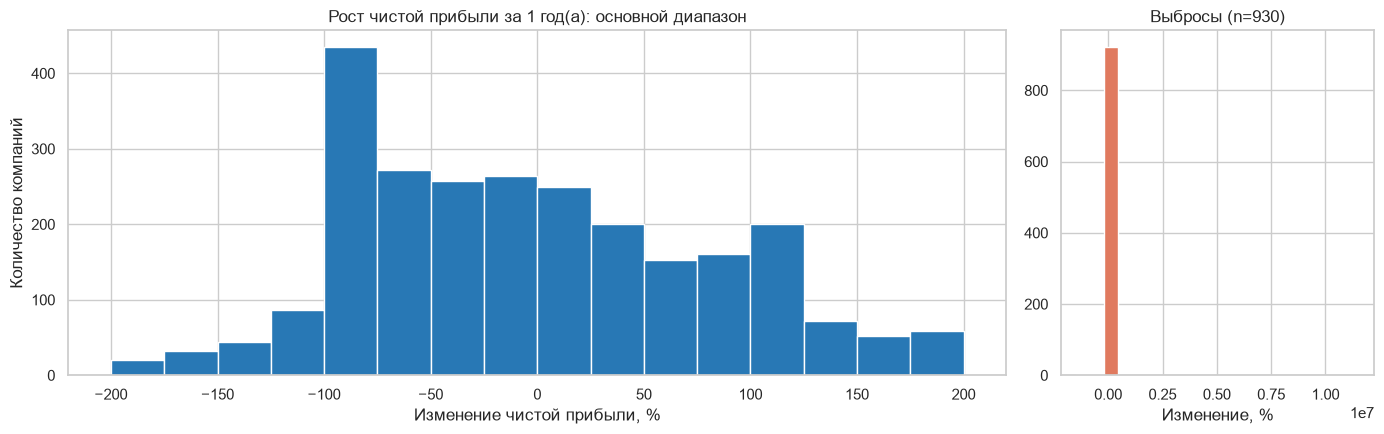

Вывод: для интервала 1 год(а) рассчитано наблюдений: 3487; медиана темпа 0.8%. Переходы: {'Остальные': 2478, 'Прибыль → убыток': 374, 'Убыток → убыток': 372, 'Убыток → прибыль': 263}.


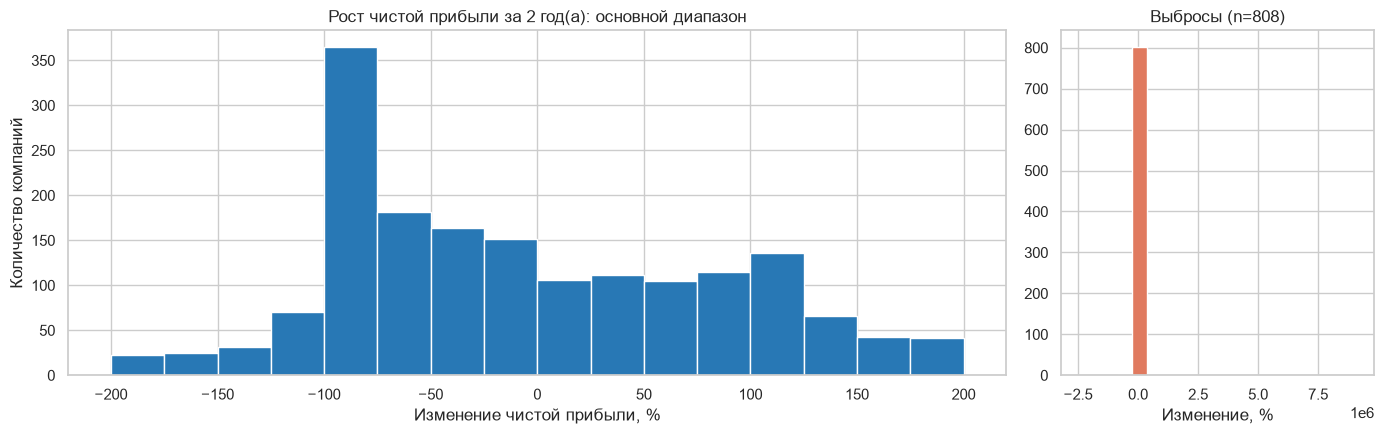

Вывод: для интервала 2 год(а) рассчитано наблюдений: 2543; медиана темпа 1.1%. Переходы: {'Остальные': 1769, 'Прибыль → убыток': 336, 'Убыток → убыток': 226, 'Убыток → прибыль': 212}.


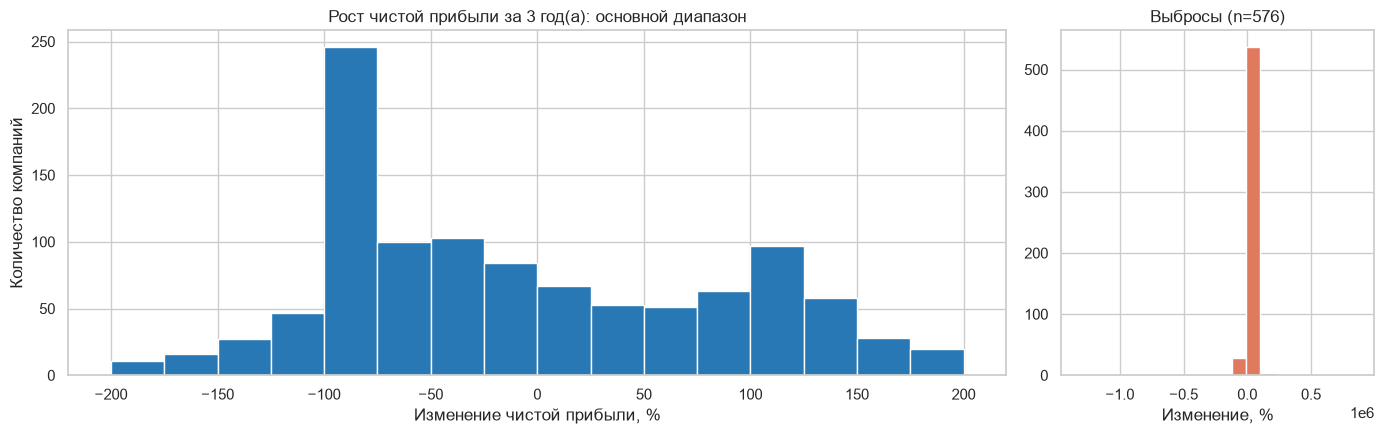

Вывод: для интервала 3 год(а) рассчитано наблюдений: 1647; медиана темпа -1.7%. Переходы: {'Остальные': 1118, 'Прибыль → убыток': 254, 'Убыток → прибыль': 144, 'Убыток → убыток': 131}.


,"Интервал, лет",Компаний с темпом,"Средний темп, %","Медианный темп, %","Доля прибыльных, %","Доля убыточных, %",Убыток → прибыль,Прибыль → убыток,Убыток → убыток
0,1,3487,1930.612723,0.807996,68.623482,26.012146,263,374,372
1,2,2543,3684.579467,1.071155,68.623482,26.012146,212,336,226
2,3,1647,-632.005544,-1.696479,68.623482,26.012146,144,254,131


In [8]:

profit_col = "Чистая прибыль"
profit_summary_rows = []

def make_growth_data(year_gap):
    if financial_data.empty or profit_col not in financial_data:
        return pd.DataFrame(columns=["ИНН", "Год", "Рост, %", "Переход"])
    wide = financial_data.pivot_table(index="ИНН", columns="Год", values=profit_col, aggfunc="last")
    pairs = []
    for current_year in sorted(wide.columns):
        previous_year = current_year - year_gap
        if previous_year not in wide.columns:
            continue
        current = wide[current_year]
        previous = wide[previous_year]
        valid = (current.notna() & previous.notna() & previous.ne(0)).fillna(False)
        out = pd.DataFrame({"ИНН": wide.index[valid], "Год": current_year,
                            "Рост, %": (current[valid] - previous[valid]) / previous[valid].abs() * 100,
                            "Прибыль базового года": previous[valid], "Прибыль текущего года": current[valid]})
        out["Переход"] = np.select(
            [out["Прибыль базового года"].lt(0) & out["Прибыль текущего года"].gt(0),
             out["Прибыль базового года"].gt(0) & out["Прибыль текущего года"].lt(0),
             out["Прибыль базового года"].lt(0) & out["Прибыль текущего года"].lt(0)],
            ["Убыток → прибыль", "Прибыль → убыток", "Убыток → убыток"], default="Остальные"
        )
        pairs.append(out)
    return pd.concat(pairs, ignore_index=True) if pairs else pd.DataFrame(columns=["ИНН", "Год", "Рост, %", "Переход"])

for gap in (1, 2, 3):
    growth = make_growth_data(gap)
    n = len(growth)
    profitable = financial_data.loc[financial_data[profit_col].notna()].groupby("ИНН")[profit_col].last() if not financial_data.empty else pd.Series(dtype=float)
    profit_summary_rows.append({"Интервал, лет": gap, "Компаний с темпом": n,
        "Средний темп, %": growth["Рост, %"].mean() if n else np.nan,
        "Медианный темп, %": growth["Рост, %"].median() if n else np.nan,
        "Доля прибыльных, %": (profitable.gt(0).mean() * 100) if len(profitable) else np.nan,
        "Доля убыточных, %": (profitable.lt(0).mean() * 100) if len(profitable) else np.nan,
        "Убыток → прибыль": int(growth["Переход"].eq("Убыток → прибыль").sum()),
        "Прибыль → убыток": int(growth["Переход"].eq("Прибыль → убыток").sum()),
        "Убыток → убыток": int(growth["Переход"].eq("Убыток → убыток").sum())})
    if n:
        inside = growth[growth["Рост, %"].between(-200, 200).fillna(False)]
        outside = growth[~growth.index.isin(inside.index)]
        bins = np.arange(-200, 225, 25)
        fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [3, 1]})
        axes[0].hist(inside["Рост, %"], bins=bins, color="#2878B5", edgecolor="white")
        axes[0].set_title(f"Рост чистой прибыли за {gap} год(а): основной диапазон")
        axes[0].set_xlabel("Изменение чистой прибыли, %")
        axes[0].set_ylabel("Количество компаний")
        axes[1].hist(outside["Рост, %"], bins=20, color="#E07A5F", edgecolor="white")
        axes[1].set_title(f"Выбросы (n={len(outside)})")
        axes[1].set_xlabel("Изменение, %")
        fig.tight_layout()
        fig.savefig(FIGURE_DIR / f"profit_growth_{gap}y.png", dpi=160, bbox_inches="tight")
        plt.show()
        print(f"Вывод: для интервала {gap} год(а) рассчитано наблюдений: {n}; медиана темпа {growth['Рост, %'].median():.1f}%. Переходы: {growth['Переход'].value_counts().to_dict()}.")
    else:
        print(f"Для интервала {gap} год(а) недостаточно сопоставимых данных для графика.")

profit_summary = pd.DataFrame(profit_summary_rows)
display(profit_summary)

## 7. Сопоставимая динамика

In [9]:

comparable_rows = []
if not financial_data.empty:
    for metric in ["Выручка", "Чистая прибыль", "EBITDA"]:
        if metric not in financial_data:
            continue
        wide = financial_data.pivot_table(index="ИНН", columns="Год", values=metric, aggfunc="last")
        for year in sorted(wide.columns):
            prev_year = year - 1
            if prev_year not in wide:
                continue
            pair = wide[[prev_year, year]].dropna()
            comparable_rows.append({"Показатель": metric, "Год": year, "Компаний в сопоставимой выборке": len(pair),
                                    "Сумма в прошлом году": pair[prev_year].sum() if len(pair) else np.nan,
                                    "Сумма в текущем году": pair[year].sum() if len(pair) else np.nan,
                                    "Изменение, %": ((pair[year].sum() / pair[prev_year].sum() - 1) * 100
                                                     if len(pair) and pair[prev_year].sum() != 0 else np.nan)})
comparable_summary = pd.DataFrame(comparable_rows)
display(comparable_summary)

,Показатель,Год,Компаний в сопоставимой выборке,Сумма в прошлом году,Сумма в текущем году,"Изменение, %"
0,Выручка,2022,920,245948502.0,256866747.0,4.439240
1,Выручка,2023,899,260493715.0,321519688.0,23.427042
2,Выручка,2024,838,312683632.0,337163037.0,7.828809
3,Выручка,2025,785,323531335.0,326470683.0,0.908520
4,Чистая прибыль,2022,927,10213756.0,6831908.0,-33.110719
5,Чистая прибыль,2023,918,7640394.0,17845925.0,133.573360
6,Чистая прибыль,2024,858,18373789.0,14326838.0,-22.025675
7,Чистая прибыль,2025,818,15043859.0,10711541.0,-28.797917
8,EBITDA,2022,15,2538033.0,1414153.0,-44.281536
9,EBITDA,2023,12,1403171.0,1147481.0,-18.222298


## 8. Топ-500 и карта

Координаты берутся по населённым пунктам из реестра; неизвестные точки не подставляются.

,ИНН,Название,Выручка,Регион,Адрес регистрации
0,9717108903,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АИР ...",7211988.0,77 - г.Москва,77 - г.Москва
1,7712103721,"АКЦИОНЕРНОЕ ОБЩЕСТВО ""ТЕПЛОИНДУСТРИЯ""",6079192.0,77 - г.Москва,77 - г.Москва
2,1655211533,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АПЕКС""",5934378.0,16 - Республика Татарстан (Татарстан),"16 - Республика Татарстан (Татарстан), г Казань"
3,7816300957,"АКЦИОНЕРНОЕ ОБЩЕСТВО СТРОИТЕЛЬНАЯ КОМПАНИЯ ""КО...",5849564.0,78 - г.Санкт-Петербург,78 - г.Санкт-Петербург
4,7806056530,"ЗАКРЫТОЕ АКЦИОНЕРНОЕ ОБЩЕСТВО ""СТРОИТЕЛЬНАЯ КО...",5744991.0,78 - г.Санкт-Петербург,78 - г.Санкт-Петербург
5,1657102836,"АКЦИОНЕРНОЕ ОБЩЕСТВО ""ТСНРУ""",4458544.0,77 - г.Москва,77 - г.Москва
6,9715426146,"АКЦИОНЕРНОЕ ОБЩЕСТВО ""МР-ЦЕНТР""",3870268.0,77 - г.Москва,77 - г.Москва
7,6671268279,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АТЛА...",3353417.0,66 - Свердловская область,"66 - Свердловская область, г Екатеринбург"
8,2543051851,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АТР-...",3291274.0,25 - Приморский край,"25 - Приморский край, г Владивосток"
9,4703142302,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АРСЕ...",3260590.0,47 - Ленинградская область,"47 - Ленинградская область, Всеволожский р-н, ..."


,Регион,Компаний
0,77 - г.Москва,96
1,78 - г.Санкт-Петербург,50
2,50 - Московская область,35
3,16 - Республика Татарстан (Татарстан),22
4,66 - Свердловская область,21
5,23 - Краснодарский край,16
6,54 - Новосибирская область,14
7,25 - Приморский край,10
8,62 - Рязанская область,10
9,63 - Самарская область,9


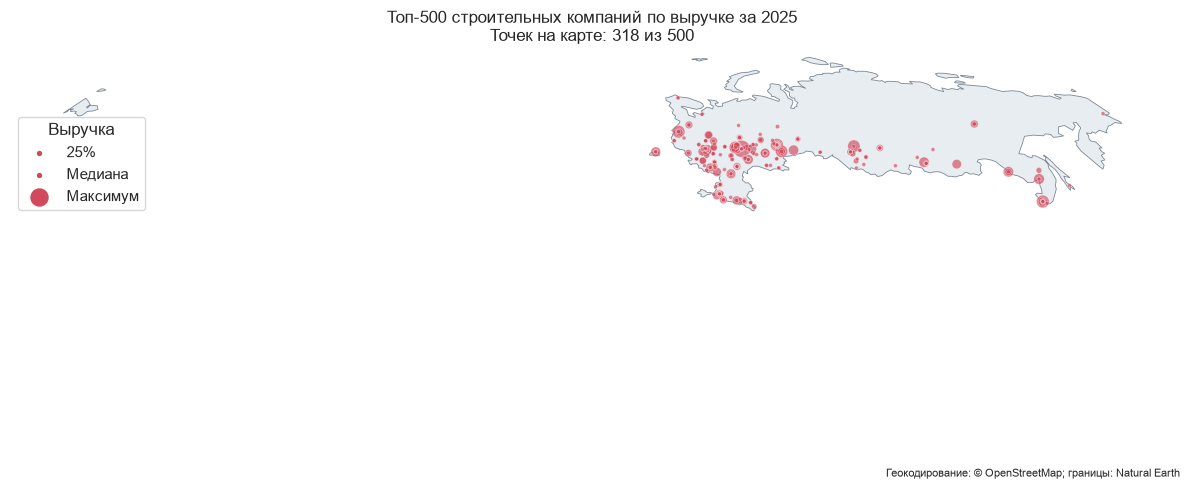

In [10]:

latest_year = int(financial_data.loc[financial_data["Выручка"].notna(), "Год"].max())
latest = financial_data[(financial_data["Год"] == latest_year) & financial_data["Выручка"].notna()]
top500 = latest.sort_values("Выручка", ascending=False).drop_duplicates("ИНН").head(500)
places = construction[["ИНН", "Адрес регистрации", "Город", "Населенный пункт"]]
top500 = top500.merge(places, on="ИНН", how="left")
top500["Место"] = top500["Город"].fillna(top500["Населенный пункт"])
top500["Регион поиска"] = top500["Регион"].astype(str).str.replace(r"^\s*\d+\s*-\s*", "", regex=True)
top500["Запрос"] = top500["Место"].astype("string") + ", " + top500["Регион поиска"] + ", Россия"
top500.loc[top500["Место"].isna(), "Запрос"] = pd.NA


cache_file = BASE_DIR / "geocode_cache.parquet"
cache = pd.read_parquet(cache_file) if cache_file.exists() else pd.DataFrame(
    columns=["Запрос", "Широта", "Долгота"])
cache = cache.drop_duplicates("Запрос", keep="last")
known = set(cache["Запрос"].dropna())
for query in top500["Запрос"].dropna().unique():
    if query in known:
        continue
    response = requests.get(
        "https://nominatim.openstreetmap.org/search",
        params={"q": query, "format": "jsonv2", "limit": 1, "countrycodes": "ru"},
        headers={"User-Agent": "ConstructionIndustryAnalysisNotebook/1.0"}, timeout=30
    )
    response.raise_for_status()
    result = response.json()
    cache.loc[len(cache)] = [query, float(result[0]["lat"]) if result else np.nan,
                             float(result[0]["lon"]) if result else np.nan]
    known.add(query)
    cache.to_parquet(cache_file, index=False)
    time.sleep(1.1)

top500 = top500.merge(cache, left_on="Запрос", right_on="Запрос", how="left")
top500["Точность координат"] = np.where(top500["Широта"].notna(), "населённый пункт", "не определена")
top500.to_parquet(BASE_DIR / "top500.parquet", index=False)
top_regions = top500["Регион"].value_counts().head(10).rename_axis("Регион").reset_index(name="Компаний")
display(top500[["ИНН", "Название", "Выручка", "Регион", "Адрес регистрации"]].head(20))
display(top_regions)


map_file = BASE_DIR / "naturalearth" / "ne_110m_admin_0_countries.shp"
if not map_file.exists():
    import zipfile
    import io
    folder = BASE_DIR / "naturalearth"
    folder.mkdir(exist_ok=True)
    data = requests.get("https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip", timeout=30)
    data.raise_for_status()
    zipfile.ZipFile(io.BytesIO(data.content)).extractall(folder)
world = gpd.read_file(map_file)
russia = world[world["ADMIN"] == "Russia"].to_crs("+proj=robin +datum=WGS84 +units=m +no_defs")
points = top500.dropna(subset=["Широта", "Долгота"]).copy()
points = points[points["Широта"].between(40, 82) & points["Долгота"].between(19, 180)]
points = gpd.GeoDataFrame(points, geometry=gpd.points_from_xy(points["Долгота"], points["Широта"]), crs="EPSG:4326").to_crs(russia.crs)
fig, ax = plt.subplots(figsize=(12, 7))
russia.plot(ax=ax, color="#e8edf2", edgecolor="#7b8794", linewidth=0.6)
size = np.clip(points["Выручка"] / points["Выручка"].max() * 150, 8, 150)
points.plot(ax=ax, color="#d1495b", alpha=0.65, markersize=size, edgecolor="white", linewidth=0.3)
for value, label in zip(points["Выручка"].quantile([0.25, 0.5, 1]), ["25%", "Медиана", "Максимум"]):
    ax.scatter([], [], s=np.clip(value / points["Выручка"].max() * 150, 8, 150), color="#d1495b", label=label)
ax.legend(title="Выручка", loc="lower left")
ax.set_title(f"Топ-500 строительных компаний по выручке за {latest_year}\nТочек на карте: {len(points)} из {len(top500)}")
ax.set_axis_off()
fig.text(0.99, 0.01, "Геокодирование: © OpenStreetMap; границы: Natural Earth", ha="right", fontsize=8)
plt.tight_layout()
fig.savefig(FIGURE_DIR / "top500_map.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Выводы

Амортизация и координаты не подставляются, если их нет в источниках. Итоги ограничены доступностью и полнотой данных ФНС.


In [11]:
net_summary = financial_data.groupby("Год").agg(
    Компаний=("Чистая прибыль", "count"),
    Совокупная_чистая_прибыль=("Чистая прибыль", "sum"),
    Доля_убыточных=("Чистая прибыль", lambda s: (s.dropna() < 0).mean() if s.notna().any() else np.nan)
)
display(net_summary)


,Компаний,Совокупная_чистая_прибыль,Доля_убыточных
Год,,,
2021,937,10158732.0,0.165422
2022,976,7366276.0,0.195697
2023,923,17903485.0,0.198267
2024,865,14354186.0,0.213873
2025,825,10718404.0,0.254545
